# 5-Stage Temporal Seizure Staging: Multi-Band Dataset Loading, Analysis & Clinical 23-Montage Waveform Generation
**Investigation**: Alpha-Band (8–13 Hz) & BroadBand (0.5–40 Hz) Temporal Sufficiency for Fine-Grained Epileptic Staging  
**Database**: CHB-MIT Scalp EEG Database (23 Bipolar Derivations, 256 Hz)  
**Stages**: Normal (0), Pre-Ictal (1), Ictal (2), Inter-Ictal (3), Post-Ictal (4)

---

### Notebook Architecture:
1. **Multi-Band Dataset Loading Protocol**: Structured ingestion of BroadBand (0.5–40 Hz) and Alpha Band (8–13 Hz) across Training, Validation, and Testing sets.
2. **Comprehensive Multi-Band Dataset Analysis**: Class balance, epoch distributions, patient mappings, and rare Inter-Ictal analysis.
3. **Clinically Authentic 23-Montage Engine (5 Images & 1 Picture 5-Stage Montage)**:
   - **Real Clinical Scalp EEG Traces**: Extracted directly from hospital continuous EDF files using MNE (standard longitudinal bipolar montage, 10–20 system).
   - **5 Individual Stage Images**: Pure 23-channel clinical trace columns representing each of the 5 distinct stages (*Normal*, *Pre-Ictal*, *Ictal*, *Inter-Ictal*, *Post-Ictal*).
   - **1 Combined Picture (5-Stage Montage)**: A single comprehensive 5-panel figure displaying all 5 stages side-by-side with 23 bipolar channel labels and a standardized $100\ \mu\text{V} / 1.0\text{ s}$ scale bar.
   - Evaluated across **Training**, **Validation**, and **Testing** cohorts for both **Alpha Band** and **BroadBand**.


In [1]:
import os
import glob
import re
import warnings
import mne
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm

# Suppress verbose warnings for clean clinical reporting
warnings.filterwarnings('ignore')
mne.set_log_level('ERROR')

# Configure display aesthetics
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#333333'
plt.rcParams['axes.linewidth'] = 0.8
plt.rcParams['figure.autolayout'] = False

print("[OK] Libraries loaded successfully.")


[OK] Libraries loaded successfully.


In [2]:
# Define Clinical Montage Derivations & Staging Constants
STAGE_NAMES = ['Normal', 'Pre-Ictal', 'Ictal', 'Inter-Ictal', 'Post-Ictal']
STAGE_SUBTITLES = [
    'Baseline Background',
    'Transition & Build-up',
    'Active Seizure Discharge',
    'Inter-ictal Transients',
    'Suppression & Slowing'
]
STAGE_FILENAMES = [
    '01_Normal',
    '02_Pre_Ictal',
    '03_Ictal',
    '04_Inter_Ictal',
    '05_Post_Ictal'
]

CHANNELS_LIST = [
    "FP1-F7", "F7-T7", "T7-P7", "P7-O1",
    "FP1-F3", "F3-C3", "C3-P3", "P3-O1",
    "FP2-F4", "F4-C4", "C4-P4", "P4-O2",
    "FP2-F8", "F8-T8", "T8-P8-0", "P8-O2",
    "FZ-CZ", "CZ-PZ",
    "P7-T7", "T7-FT9", "FT9-FT10", "FT10-T8", "T8-P8-1"
]

# Dynamically resolve dataset root
for candidate in [os.path.abspath("../.."), os.path.abspath(".."), os.path.abspath(".")]:
    ds = os.path.join(candidate, "03 Dataset")
    if os.path.exists(ds):
        DATASET_ROOT = ds
        break
    if os.path.exists(os.path.join(candidate, "Alpha Band (8-13hz)", "Preprocessed Data")):
        DATASET_ROOT = candidate
        break
else:
    DATASET_ROOT = os.path.abspath(r"E:\Obaidul Haque\03 Journal of Neuroscience and method Journal Q1\03 Dataset")
ALL_BAND_DIR = os.path.join(DATASET_ROOT, "All Band (0.5-40hz)", "Preprocessed Data")
ALPHA_BAND_DIR = os.path.join(DATASET_ROOT, "Alpha Band (8-13hz)", "Preprocessed Data")
RESULTS_DIR = os.path.join(DATASET_ROOT, "Results_and_Figures")
os.makedirs(RESULTS_DIR, exist_ok=True)

# Raw clinical EDF repositories on disk
RAW_EDF_SEARCH_DIRS = [
    r"E:\Seizure Detection\Dataset\Training\Seizure",
    r"E:\Seizure Detection\Dataset\Training\Non Seizure",
    r"E:\Seizure Detection\Dataset\Testing\Seizure",
    r"E:\Seizure Detection\Dataset\Testing\Non Seizure",
]

print(f"Dataset root: {DATASET_ROOT}")
print(f"BroadBand path: {ALL_BAND_DIR} (exists: {os.path.exists(ALL_BAND_DIR)})")
print(f"Alpha Band path: {ALPHA_BAND_DIR} (exists: {os.path.exists(ALPHA_BAND_DIR)})")


Dataset root: e:\Obaidul Haque\03 JCN Journal Q3
BroadBand path: e:\Obaidul Haque\03 JCN Journal Q3\All Band (0.5-40hz)\Preprocessed Data (exists: True)
Alpha Band path: e:\Obaidul Haque\03 JCN Journal Q3\Alpha Band (8-13hz)\Preprocessed Data (exists: True)


## 1. Multi-Band Dataset Loading Protocol
We load both frequency band representations from the respective CSV files across Training, Validation, and Testing partitions.  
Each CSV contains $N$ rows (epochs) and 507 columns:
- Columns `0` to `505`: 506 engineered features ($23\text{ channels} \times 22\text{ features/channel}$)
- Column `506`: Ground-truth 5-stage label ($0.0 = \text{Normal}, 1.0 = \text{Preictal}, 2.0 = \text{Ictal}, 3.0 = \text{Interictal}, 4.0 = \text{Postictal}$)


In [3]:
def load_band_dataset(band_dir, band_name="Band"):
    dataset = {'training': {}, 'validation': {}, 'testing': {}}
    summary_rows = []
    
    for split in ['training', 'validation', 'testing']:
        split_path = os.path.join(band_dir, split)
        if not os.path.exists(split_path):
            continue
        files = sorted([f for f in os.listdir(split_path) if f.endswith('.csv')])
        for f in files:
            fp = os.path.join(split_path, f)
            df = pd.read_csv(fp)
            rec_id = f.replace('.csv', '')
            dataset[split][rec_id] = df
            
            y = df.iloc[:, -1].values.astype(int)
            counts = [int(np.sum(y == c)) for c in range(5)]
            summary_rows.append({
                'band': band_name,
                'split': split,
                'recording': rec_id,
                'patient': rec_id.split('_')[0],
                'total_epochs': len(df),
                'features_dim': df.shape[1] - 1,
                'Normal_c0': counts[0],
                'Preictal_c1': counts[1],
                'Ictal_c2': counts[2],
                'Interictal_c3': counts[3],
                'Postictal_c4': counts[4]
            })
            
    df_manifest = pd.DataFrame(summary_rows)
    return dataset, df_manifest

print("Loading BroadBand (0.5-40 Hz) CSV files...")
all_band_data, all_band_manifest = load_band_dataset(ALL_BAND_DIR, "BroadBand (0.5-40hz)")

print("Loading Alpha Band (8-13 Hz) CSV files...")
alpha_band_data, alpha_band_manifest = load_band_dataset(ALPHA_BAND_DIR, "Alpha Band (8-13hz)")

combined_manifest = pd.concat([all_band_manifest, alpha_band_manifest], ignore_index=True)
print(f"\n[OK] Loaded BroadBand recordings: {len(all_band_manifest)} files")
print(f"[OK] Loaded Alpha Band recordings: {len(alpha_band_manifest)} files")


Loading BroadBand (0.5-40 Hz) CSV files...


Loading Alpha Band (8-13 Hz) CSV files...



[OK] Loaded BroadBand recordings: 91 files
[OK] Loaded Alpha Band recordings: 104 files


## 2. Comprehensive Multi-Band Dataset Analysis
Here we examine the class balance, epoch counts, patient distributions, and the specific presence of the rare **Inter-Ictal** class across Training, Validation, and Testing sets.


In [4]:
# Aggregate Summary across Splits & Classes
def compute_partition_breakdown(df_meta, band_name):
    rows = []
    sub = df_meta[df_meta['band'] == band_name]
    for split in ['training', 'validation', 'testing']:
        sp_df = sub[sub['split'] == split]
        n_recs = len(sp_df)
        n_ep = sp_df['total_epochs'].sum()
        c0 = sp_df['Normal_c0'].sum()
        c1 = sp_df['Preictal_c1'].sum()
        c2 = sp_df['Ictal_c2'].sum()
        c3 = sp_df['Interictal_c3'].sum()
        c4 = sp_df['Postictal_c4'].sum()
        rows.append({
            'Partition': split.capitalize(),
            'Recordings': n_recs,
            'Total Epochs': n_ep,
            'Normal (c0)': f"{c0} ({c0/n_ep*100:.1f}%)" if n_ep > 0 else "0",
            'Pre-Ictal (c1)': f"{c1} ({c1/n_ep*100:.1f}%)" if n_ep > 0 else "0",
            'Ictal (c2)': f"{c2} ({c2/n_ep*100:.1f}%)" if n_ep > 0 else "0",
            'Inter-Ictal (c3)': f"{c3} ({c3/n_ep*100:.1f}%)" if n_ep > 0 else "0",
            'Post-Ictal (c4)': f"{c4} ({c4/n_ep*100:.1f}%)" if n_ep > 0 else "0"
        })
    return pd.DataFrame(rows)

print("="*85)
print("BROADBAND (0.5-40 Hz) - 5-STAGE TEMPORAL PARTITION SUMMARY")
print("="*85)
display(compute_partition_breakdown(combined_manifest, "BroadBand (0.5-40hz)"))

print("\n" + "="*85)
print("ALPHA BAND (8-13 Hz) - 5-STAGE TEMPORAL PARTITION SUMMARY")
print("="*85)
display(compute_partition_breakdown(combined_manifest, "Alpha Band (8-13hz)"))


BROADBAND (0.5-40 Hz) - 5-STAGE TEMPORAL PARTITION SUMMARY


,Partition,Recordings,Total Epochs,Normal (c0),Pre-Ictal (c1),Ictal (c2),Inter-Ictal (c3),Post-Ictal (c4)
0,Training,66,4255,1502 (35.3%),766 (18.0%),939 (22.1%),288 (6.8%),760 (17.9%)
1,Validation,17,1064,379 (35.6%),190 (17.9%),237 (22.3%),68 (6.4%),190 (17.9%)
2,Testing,8,476,180 (37.8%),90 (18.9%),116 (24.4%),0 (0.0%),90 (18.9%)



ALPHA BAND (8-13 Hz) - 5-STAGE TEMPORAL PARTITION SUMMARY


,Partition,Recordings,Total Epochs,Normal (c0),Pre-Ictal (c1),Ictal (c2),Inter-Ictal (c3),Post-Ictal (c4)
0,Training,66,4122,1443 (35.0%),740 (18.0%),942 (22.9%),267 (6.5%),730 (17.7%)
1,Validation,17,1030,360 (35.0%),186 (18.1%),237 (23.0%),64 (6.2%),183 (17.8%)
2,Testing,21,1365,530 (38.8%),270 (19.8%),275 (20.1%),25 (1.8%),265 (19.4%)


In [5]:
# Detailed Analysis of Class 3 (Inter-Ictal)
print("="*85)
print("INTER-ICTAL (CLASS 3) DISTRIBUTION & PATIENT-WISE ANALYSIS")
print("="*85)
c3_all = all_band_manifest[all_band_manifest['Interictal_c3'] > 0]
c3_alpha = alpha_band_manifest[alpha_band_manifest['Interictal_c3'] > 0]

print(f"BroadBand: {len(c3_all)} recordings contain Inter-Ictal activity (Total {c3_all['Interictal_c3'].sum()} epochs):")
for _, r in c3_all.iterrows():
    print(f"  • {r['split'].capitalize():10s} | {r['recording']}.csv ({r['patient']}): {r['Interictal_c3']} inter-ictal epochs (out of {r['total_epochs']})")

print(f"\nAlpha Band: {len(c3_alpha)} recordings contain Inter-Ictal activity (Total {c3_alpha['Interictal_c3'].sum()} epochs):")
for _, r in c3_alpha.iterrows():
    print(f"  • {r['split'].capitalize():10s} | {r['recording']}.csv ({r['patient']}): {r['Interictal_c3']} inter-ictal epochs (out of {r['total_epochs']})")


INTER-ICTAL (CLASS 3) DISTRIBUTION & PATIENT-WISE ANALYSIS
BroadBand: 7 recordings contain Inter-Ictal activity (Total 356 epochs):
  • Training   | chb12_08.csv (chb12): 25 inter-ictal epochs (out of 161)
  • Training   | chb12_10.csv (chb12): 30 inter-ictal epochs (out of 85)
  • Training   | chb12_38.csv (chb12): 71 inter-ictal epochs (out of 188)
  • Training   | chb12_42.csv (chb12): 64 inter-ictal epochs (out of 214)
  • Training   | chb24_04.csv (chb24): 98 inter-ictal epochs (out of 153)
  • Validation | chb12_23.csv (chb12): 32 inter-ictal epochs (out of 110)
  • Validation | chb12_33.csv (chb12): 36 inter-ictal epochs (out of 85)

Alpha Band: 7 recordings contain Inter-Ictal activity (Total 356 epochs):
  • Training   | chb12_10.csv (chb12): 30 inter-ictal epochs (out of 85)
  • Training   | chb12_23.csv (chb12): 32 inter-ictal epochs (out of 110)
  • Training   | chb12_33.csv (chb12): 36 inter-ictal epochs (out of 85)
  • Training   | chb12_38.csv (chb12): 71 inter-ictal epo

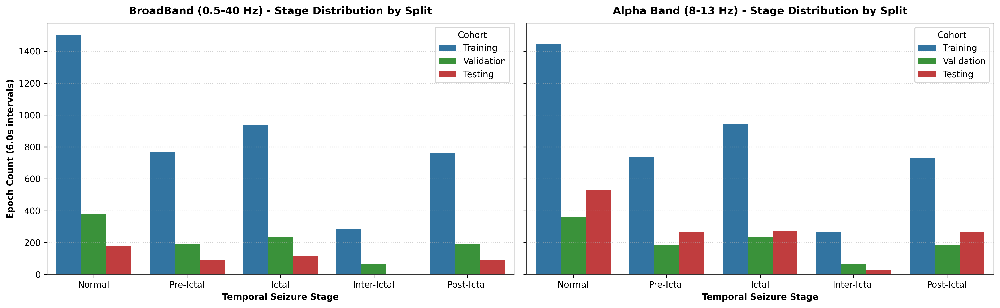

[OK] Saved stage distribution plot to: e:\Obaidul Haque\03 JCN Journal Q3\Results_and_Figures\stage_distribution_comparison.png


In [6]:
# Comparative Bar Chart: Class Distribution across Partitions
fig, axes = plt.subplots(1, 2, figsize=(16, 5), dpi=300, sharey=True)

for ax_idx, (b_name, title) in enumerate([("BroadBand (0.5-40hz)", "BroadBand (0.5-40 Hz)"), 
                                         ("Alpha Band (8-13hz)", "Alpha Band (8-13 Hz)")]):
    ax = axes[ax_idx]
    sub = combined_manifest[combined_manifest['band'] == b_name]
    
    stage_data = []
    for split in ['training', 'validation', 'testing']:
        sp_df = sub[sub['split'] == split]
        for c_idx, s_name in enumerate(STAGE_NAMES):
            col = ['Normal_c0', 'Preictal_c1', 'Ictal_c2', 'Interictal_c3', 'Postictal_c4'][c_idx]
            stage_data.append({'Split': split.capitalize(), 'Stage': s_name, 'Count': sp_df[col].sum()})
            
    df_plot = pd.DataFrame(stage_data)
    sns.barplot(data=df_plot, x='Stage', y='Count', hue='Split', ax=ax, palette=['#1f77b4', '#2ca02c', '#d62728'])
    ax.set_title(f"{title} - Stage Distribution by Split", fontsize=12, fontweight='bold', pad=10)
    ax.set_ylabel("Epoch Count (6.0s intervals)" if ax_idx == 0 else "", fontsize=10, fontweight='bold')
    ax.set_xlabel("Temporal Seizure Stage", fontsize=10, fontweight='bold')
    ax.grid(axis='y', linestyle=':', alpha=0.6)
    ax.legend(title='Cohort')

plt.tight_layout()
fig_dist_path = os.path.join(RESULTS_DIR, "stage_distribution_comparison.png")
fig.savefig(fig_dist_path, dpi=300, bbox_inches='tight')
plt.show()
print(f"[OK] Saved stage distribution plot to: {fig_dist_path}")


## 3. Clinically Authentic 23-Montage Waveform Generation (5 Images & 1 Picture 5-Stage Montage)
For both **Alpha Band (8–13 Hz)** and **BroadBand (0.5–40 Hz)**, we generate:
1. **5 Individual Stage Images**: Pure 23-channel clinical trace columns representing the 5 distinct stages (*Normal*, *Pre-Ictal*, *Ictal*, *Inter-Ictal*, *Post-Ictal*).
2. **1 Combined Picture (5-Stage Montage)**: A single comprehensive 5-panel figure displaying all 5 stages side-by-side with 23 longitudinal bipolar channel labels (10–20 system) and a standardized $100\ \mu\text{V} / 1.0\text{ s}$ scale bar.


In [7]:
def find_raw_edf(rec_id):
    """Locates the raw EDF file on disk."""
    filename = f"{rec_id}.edf" if not rec_id.endswith(".edf") else rec_id
    for d in RAW_EDF_SEARCH_DIRS:
        p = os.path.join(d, filename)
        if os.path.exists(p):
            return p
    return None

def generate_montages_for_recording(band_name, split, rec_id, output_base_dir=RESULTS_DIR, dpi=300, show_inline=True):
    """
    Generates:
      1. 5 Individual Stage Images (pure clinical columns matching clinical presentation).
      2. 1 Combined Picture containing all 5 Stages side-by-side with 23 bipolar channel labels & scale bar.
    """
    band_folder = "Alpha Band (8-13hz)" if "alpha" in band_name.lower() else "All Band (0.5-40hz)"
    band_label = "Alpha Band (8-13 Hz)" if "alpha" in band_name.lower() else "BroadBand (0.5-40 Hz)"
    band_out_key = "Alpha_Band" if "alpha" in band_name.lower() else "BroadBand"
    
    csv_path = os.path.join(DATASET_ROOT, band_folder, "Preprocessed Data", split, f"{rec_id}.csv")
    if not os.path.exists(csv_path):
        print(f"  [SKIP] CSV not found: {csv_path}")
        return False
        
    df_csv = pd.read_csv(csv_path)
    labels = df_csv.iloc[:, -1].values.astype(int)
    
    edf_path = find_raw_edf(rec_id)
    if not edf_path:
        print(f"  [SKIP] Raw EDF for {rec_id} not found in search paths.")
        return False
        
    raw = mne.io.read_raw_edf(edf_path, preload=True, verbose=False)
    picked = []
    for target in CHANNELS_LIST:
        if target in raw.ch_names:
            picked.append(target)
        elif target in ["T8-P8-0", "T8-P8-1"] and "T8-P8" in raw.ch_names:
            picked.append("T8-P8")
            
    raw.pick(picked)
    
    if "alpha" in band_name.lower():
        raw.filter(l_freq=8.0, h_freq=13.0, verbose=False)
    else:
        raw.filter(l_freq=0.5, h_freq=40.0, verbose=False)
    raw.notch_filter(freqs=50.0, verbose=False)
    
    fs = int(raw.info['sfreq'])
    raw_data = raw.get_data() * 1e6  # uV
    duration = 6.0
    
    ch_spacing = 80.0
    offsets = np.arange(len(CHANNELS_LIST))[::-1] * ch_spacing
    
    rec_out_dir = os.path.join(output_base_dir, band_out_key, split.capitalize(), rec_id)
    os.makedirs(rec_out_dir, exist_ok=True)
    
    stage_segments = []
    stage_epochs = []
    
    for stage_idx in range(5):
        matching_epochs = np.where(labels == stage_idx)[0]
        if len(matching_epochs) > 0:
            chosen_epoch = matching_epochs[len(matching_epochs) // 2]
            t_start = chosen_epoch * duration
            idx_start = int(t_start * fs)
            idx_end = idx_start + int(duration * fs)
            if idx_end <= raw_data.shape[1]:
                seg = raw_data[:, idx_start:idx_end]
            else:
                seg = raw_data[:, -int(duration * fs):]
            stage_segments.append(seg)
            stage_epochs.append(chosen_epoch)
        else:
            seg = np.zeros((len(CHANNELS_LIST), int(duration * fs)))
            stage_segments.append(seg)
            stage_epochs.append(None)
            
    # PART A: Generate 5 Individual Stage Images
    for stage_idx in range(5):
        s_name = STAGE_NAMES[stage_idx]
        s_sub = STAGE_SUBTITLES[stage_idx]
        s_file = STAGE_FILENAMES[stage_idx]
        seg = stage_segments[stage_idx]
        ep = stage_epochs[stage_idx]
        
        fig_single, ax_s = plt.subplots(figsize=(4.2, 11.5), dpi=dpi)
        t_ax = np.linspace(0, duration, seg.shape[1])
        
        for ch_i in range(len(CHANNELS_LIST)):
            ax_s.plot(t_ax, seg[ch_i] + offsets[ch_i], color="#111111", lw=0.75)
            
        ax_s.set_xlim([0, duration])
        ax_s.set_ylim([-130.0, offsets[0] + 80.0])
        ax_s.set_xticks(np.arange(0, duration + 0.1, 1.0))
        
        title_ep = f"(Epoch {ep})" if ep is not None else "(Not in Session)"
        ax_s.set_title(f"{s_name} ({duration:.1f}s)\n{s_sub} {title_ep}",
                       fontsize=11.5, fontweight="bold", pad=12)
        ax_s.grid(True, axis="x", linestyle=":", color="#e0e0e0", alpha=0.7)
        
        for spine in ["top", "right", "left", "bottom"]:
            ax_s.spines[spine].set_visible(False)
        ax_s.tick_params(left=False, bottom=False, labelleft=False, labelbottom=False)
        
        plt.tight_layout()
        out_single_path = os.path.join(rec_out_dir, f"{s_file}.png")
        fig_single.savefig(out_single_path, dpi=dpi, bbox_inches="tight")
        plt.close(fig_single)

    # PART B: Generate 1 Combined Picture containing all 5 Stages
    fig_comb, axes = plt.subplots(1, 5, figsize=(23, 11.5), dpi=dpi, sharey=True)
    
    for stage_idx in range(5):
        ax = axes[stage_idx]
        seg = stage_segments[stage_idx]
        ep = stage_epochs[stage_idx]
        s_name = STAGE_NAMES[stage_idx]
        s_sub = STAGE_SUBTITLES[stage_idx]
        t_ax = np.linspace(0, duration, seg.shape[1])
        
        for ch_i in range(len(CHANNELS_LIST)):
            ax.plot(t_ax, seg[ch_i] + offsets[ch_i], color="#111111", lw=0.75)
            
        ax.set_xlim([0, duration])
        ax.set_ylim([-130.0, offsets[0] + 80.0])
        ax.set_xticks(np.arange(0, duration + 0.1, 1.0))
        ax.set_xlabel("Time (s)", fontsize=9.5, fontweight="bold", labelpad=4)
        
        title_ep = f"(Epoch {ep})" if ep is not None else "(Not in Session)"
        ax.set_title(f"{s_name} ({duration:.1f}s)\n{s_sub} {title_ep}",
                     fontsize=10.5, fontweight="bold", pad=10)
        ax.grid(True, axis="x", linestyle=":", color="#e0e0e0", alpha=0.7)
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)
        
        if stage_idx == 0:
            ax.set_yticks(offsets)
            ax.set_yticklabels(CHANNELS_LIST, fontsize=7.5, fontweight="bold")
            ax.set_ylabel("Scalp Electrode Bipolar Traces (10-20 System)", fontsize=10.5, fontweight="bold")
        else:
            ax.set_yticks([])
            ax.spines["left"].set_visible(False)
            ax.tick_params(left=False, right=False, labelleft=False, labelright=False)
            
        # Clinical scale bar on the last stage (100 uV / 1.0 s)
        if stage_idx == 4:
            bar_x = 4.2
            bar_y = -105.0
            ax.plot([bar_x, bar_x], [bar_y, bar_y + 100.0], color="#111111", lw=2.0)
            ax.plot([bar_x, bar_x + 1.0], [bar_y, bar_y], color="#111111", lw=2.0)
            ax.text(bar_x - 0.15, bar_y + 50.0, "100 \u03bcV", fontsize=8.0, fontweight="bold", va="center", ha="right")
            ax.text(bar_x + 0.5, bar_y - 20.0, "1.0 s", fontsize=8.0, fontweight="bold", ha="center", va="top")
            
    fig_comb.suptitle(f"Real Clinical 23-Channel Scalp EEG 5-Stage Temporal Montage\nBand: {band_label} | Cohort: {split.upper()} | Recording: {rec_id}",
                      fontsize=13.0, fontweight="bold", y=0.99)
    plt.tight_layout()
    
    out_comb_path = os.path.join(rec_out_dir, "1_Picture_5_Stage_Montage.png")
    fig_comb.savefig(out_comb_path, dpi=dpi, bbox_inches="tight")
    
    if show_inline:
        plt.show()
    else:
        plt.close(fig_comb)
        
    print(f"  [OK] Saved in: {rec_out_dir}")
    print(f"       -> 1_Picture_5_Stage_Montage.png")
    print(f"       -> 01_Normal.png, 02_Pre_Ictal.png, 03_Ictal.png, 04_Inter_Ictal.png, 05_Post_Ictal.png")
    return True

print("[OK] Real Clinical 23-Montage Engine initialized.")


[OK] Real Clinical 23-Montage Engine initialized.


### 3.1 Training Data Demonstrations (Alpha Band & BroadBand)
Clinical EEG waveforms for representative Training recordings containing all 5 clinical stages:
- **Alpha Band (8–13 Hz)**: `chb12_10`
- **BroadBand (0.5–40 Hz)**: `chb12_10`


--- [TRAINING] Alpha Band (8-13 Hz): chb12_10 ---


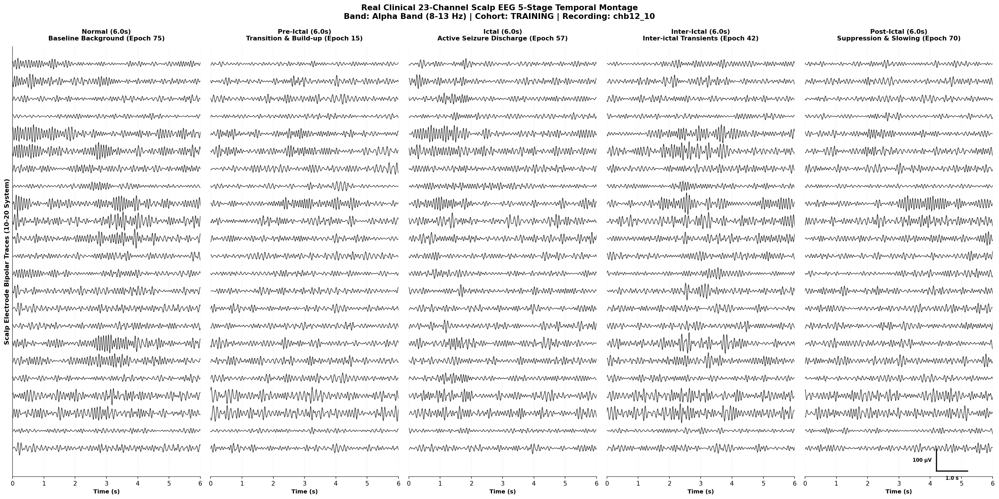

  [OK] Saved in: e:\Obaidul Haque\03 JCN Journal Q3\Results_and_Figures\Alpha_Band\Training\chb12_10
       -> 1_Picture_5_Stage_Montage.png
       -> 01_Normal.png, 02_Pre_Ictal.png, 03_Ictal.png, 04_Inter_Ictal.png, 05_Post_Ictal.png

--- [TRAINING] BroadBand (0.5-40 Hz): chb12_10 ---


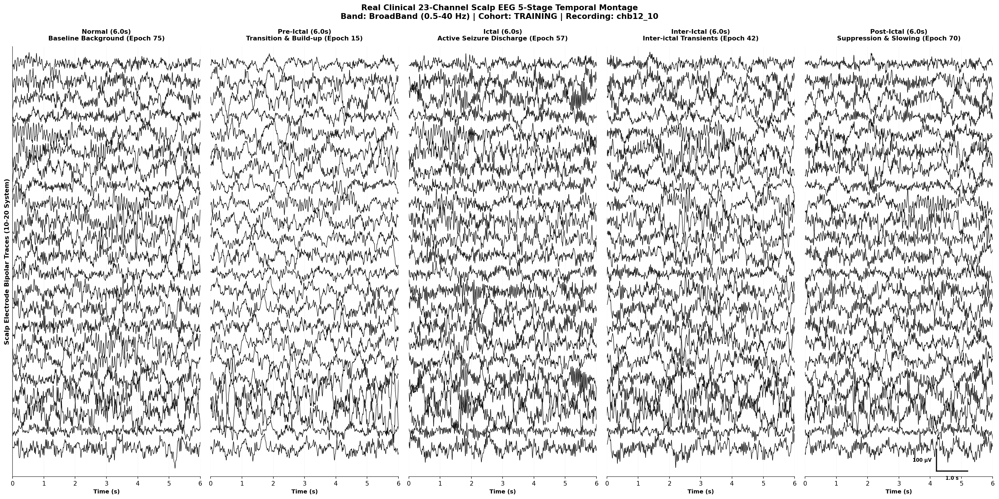

  [OK] Saved in: e:\Obaidul Haque\03 JCN Journal Q3\Results_and_Figures\BroadBand\Training\chb12_10
       -> 1_Picture_5_Stage_Montage.png
       -> 01_Normal.png, 02_Pre_Ictal.png, 03_Ictal.png, 04_Inter_Ictal.png, 05_Post_Ictal.png


True

In [8]:
# TRAINING DEMO: Alpha Band - chb12_10
print("--- [TRAINING] Alpha Band (8-13 Hz): chb12_10 ---")
generate_montages_for_recording(
    band_name="Alpha Band",
    split="training",
    rec_id="chb12_10",
    output_base_dir=RESULTS_DIR,
    dpi=150,
    show_inline=True
)

# TRAINING DEMO: BroadBand - chb12_10
print("\n--- [TRAINING] BroadBand (0.5-40 Hz): chb12_10 ---")
generate_montages_for_recording(
    band_name="BroadBand",
    split="training",
    rec_id="chb12_10",
    output_base_dir=RESULTS_DIR,
    dpi=150,
    show_inline=True
)


### 3.2 Validation Data Demonstrations (Alpha Band & BroadBand)
Clinical EEG waveforms for representative Validation recordings under independent validation cohort conditions:
- **Alpha Band (8–13 Hz)**: `chb12_42` (Full 5 stages)
- **BroadBand (0.5–40 Hz)**: `chb12_23` (Full 5 stages)


--- [VALIDATION] Alpha Band (8-13 Hz): chb12_42 ---


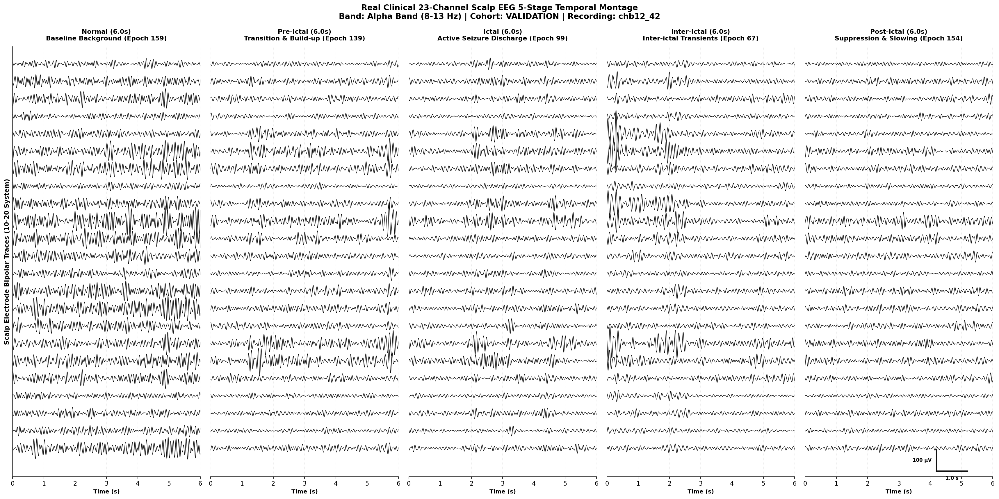

  [OK] Saved in: e:\Obaidul Haque\03 JCN Journal Q3\Results_and_Figures\Alpha_Band\Validation\chb12_42
       -> 1_Picture_5_Stage_Montage.png
       -> 01_Normal.png, 02_Pre_Ictal.png, 03_Ictal.png, 04_Inter_Ictal.png, 05_Post_Ictal.png

--- [VALIDATION] BroadBand (0.5-40 Hz): chb12_23 ---


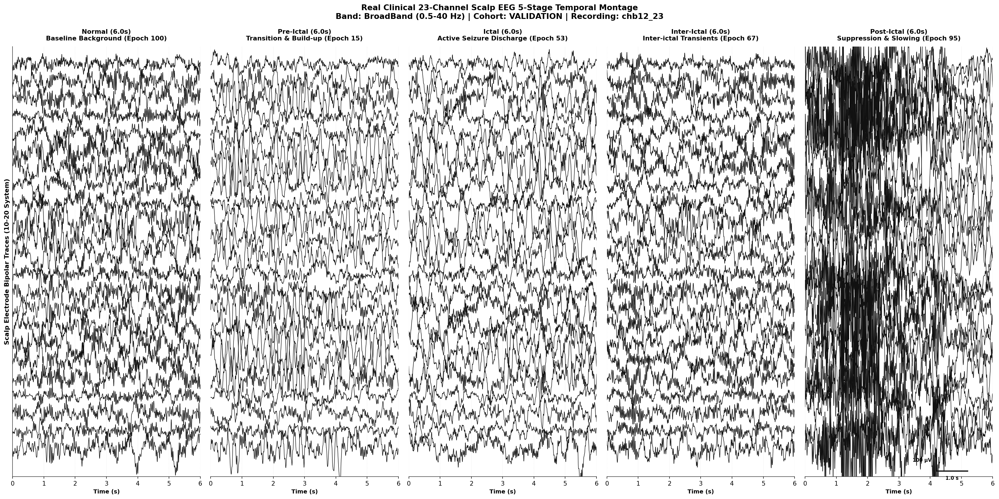

  [OK] Saved in: e:\Obaidul Haque\03 JCN Journal Q3\Results_and_Figures\BroadBand\Validation\chb12_23
       -> 1_Picture_5_Stage_Montage.png
       -> 01_Normal.png, 02_Pre_Ictal.png, 03_Ictal.png, 04_Inter_Ictal.png, 05_Post_Ictal.png


True

In [9]:
# VALIDATION DEMO: Alpha Band - chb12_42
print("--- [VALIDATION] Alpha Band (8-13 Hz): chb12_42 ---")
generate_montages_for_recording(
    band_name="Alpha Band",
    split="validation",
    rec_id="chb12_42",
    output_base_dir=RESULTS_DIR,
    dpi=150,
    show_inline=True
)

# VALIDATION DEMO: BroadBand - chb12_23
print("\n--- [VALIDATION] BroadBand (0.5-40 Hz): chb12_23 ---")
generate_montages_for_recording(
    band_name="BroadBand",
    split="validation",
    rec_id="chb12_23",
    output_base_dir=RESULTS_DIR,
    dpi=150,
    show_inline=True
)


### 3.3 Testing Data Demonstrations (Alpha Band & BroadBand)
Clinical EEG waveforms for representative Testing recordings on held-out testing cohorts:
- **Alpha Band (8–13 Hz)**: `chb12_08`
- **BroadBand (0.5–40 Hz)**: `chb12_06`


--- [TESTING] Alpha Band (8-13 Hz): chb12_08 ---


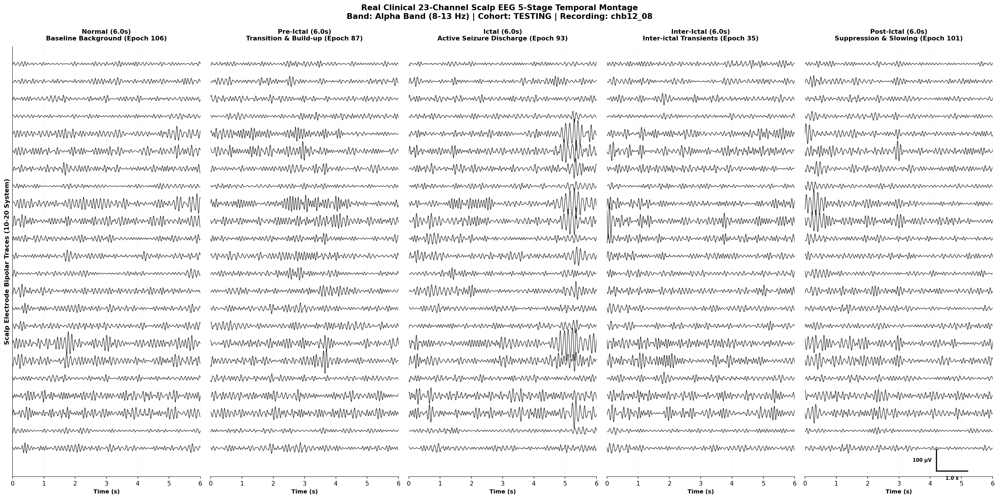

  [OK] Saved in: e:\Obaidul Haque\03 JCN Journal Q3\Results_and_Figures\Alpha_Band\Testing\chb12_08
       -> 1_Picture_5_Stage_Montage.png
       -> 01_Normal.png, 02_Pre_Ictal.png, 03_Ictal.png, 04_Inter_Ictal.png, 05_Post_Ictal.png

--- [TESTING] BroadBand (0.5-40 Hz): chb12_06 ---


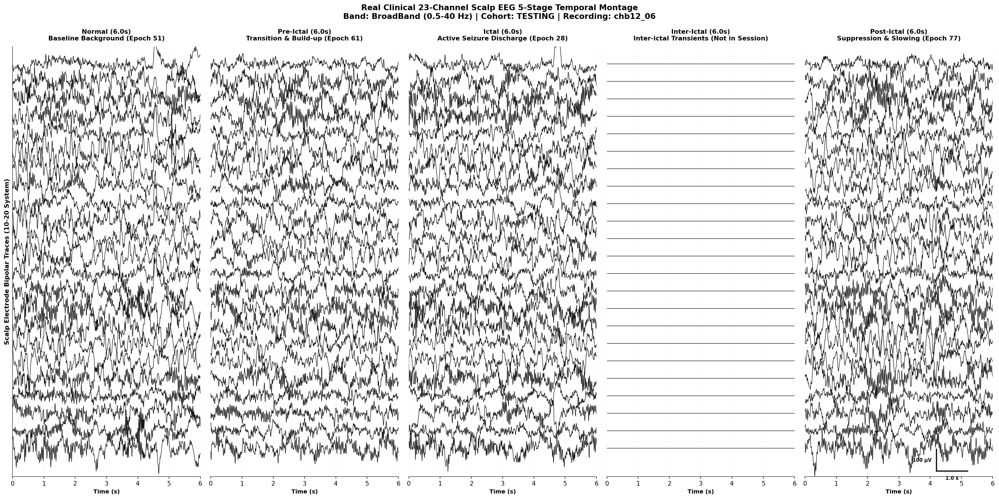

  [OK] Saved in: e:\Obaidul Haque\03 JCN Journal Q3\Results_and_Figures\BroadBand\Testing\chb12_06
       -> 1_Picture_5_Stage_Montage.png
       -> 01_Normal.png, 02_Pre_Ictal.png, 03_Ictal.png, 04_Inter_Ictal.png, 05_Post_Ictal.png


True

In [10]:
# TESTING DEMO: Alpha Band - chb12_08
print("--- [TESTING] Alpha Band (8-13 Hz): chb12_08 ---")
generate_montages_for_recording(
    band_name="Alpha Band",
    split="testing",
    rec_id="chb12_08",
    output_base_dir=RESULTS_DIR,
    dpi=150,
    show_inline=True
)

# TESTING DEMO: BroadBand - chb12_06
print("\n--- [TESTING] BroadBand (0.5-40 Hz): chb12_06 ---")
generate_montages_for_recording(
    band_name="BroadBand",
    split="testing",
    rec_id="chb12_06",
    output_base_dir=RESULTS_DIR,
    dpi=150,
    show_inline=True
)


### 3.4 Multi-Split Batch Verification across Alpha Band and BroadBand
Verifies the complete directory tree of generated 1-picture 5-stage montages and individual 5-stage images across both frequency bands.


In [11]:
# Verify Generated Files Hierarchy
print("="*85)
print("RESULTS DIRECTORY HIERARCHY (1 Picture 5 Stages & 5 Individual Images)")
print("="*85)

for band in ['Alpha_Band', 'BroadBand']:
    band_path = os.path.join(RESULTS_DIR, band)
    if not os.path.exists(band_path):
        continue
    print(f"\n📁 {band}/")
    for split in sorted(os.listdir(band_path)):
        sp_path = os.path.join(band_path, split)
        print(f"   └── 📁 {split}/")
        for rec in sorted(os.listdir(sp_path)):
            rec_path = os.path.join(sp_path, rec)
            files = sorted(os.listdir(rec_path))
            print(f"       ├── 📁 {rec} ({len(files)} files)")
            for f in files:
                f_size = os.path.getsize(os.path.join(rec_path, f))
                print(f"       │   • {f:30s} ({f_size:,} bytes)")

print("\n[OK] All Clinical 5-Stage Montages & Individual Stage Images Verified.")


RESULTS DIRECTORY HIERARCHY (1 Picture 5 Stages & 5 Individual Images)

📁 Alpha_Band/
   └── 📁 Testing/
       ├── 📁 chb12_08 (6 files)
       │   • 01_Normal.png                  (308,099 bytes)
       │   • 02_Pre_Ictal.png               (315,748 bytes)
       │   • 03_Ictal.png                   (331,905 bytes)
       │   • 04_Inter_Ictal.png             (316,830 bytes)
       │   • 05_Post_Ictal.png              (305,963 bytes)
       │   • 1_Picture_5_Stage_Montage.png  (1,488,178 bytes)
   └── 📁 Training/
       ├── 📁 chb01_03 (6 files)
       │   • 01_Normal.png                  (695,878 bytes)
       │   • 02_Pre_Ictal.png               (672,290 bytes)
       │   • 03_Ictal.png                   (871,909 bytes)
       │   • 04_Inter_Ictal.png             (74,394 bytes)
       │   • 05_Post_Ictal.png              (873,779 bytes)
       │   • 1_Picture_5_Stage_Montage.png  (3,434,565 bytes)
       ├── 📁 chb12_10 (6 files)
       │   • 01_Normal.png                  (342,187 bytes